In [1]:
# This cell is mandatory in all Dymos documentation notebooks.
missing_packages = []
try:
    import openmdao.api as om  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !python -m pip install openmdao[notebooks]
    else:
        missing_packages.append('openmdao')
try:
    import dymos as dm  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !python -m pip install dymos
    else:
        missing_packages.append('dymos')
try:
    import pyoptsparse  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !pip install -q condacolab
        import condacolab
        condacolab.install_miniconda()
        !conda install -c conda-forge pyoptsparse
    else:
        missing_packages.append('pyoptsparse')
if missing_packages:
    raise EnvironmentError('This notebook requires the following packages '
                           'please install them and restart this notebook\'s runtime: {",".join(missing_packages)}')

# Hyper-Sensitive Problem

This example is based on the Hyper-Sensitive problem given in
Patterson {cite}`patterson2015ph`. In this problem we seek to minimize both
the distance traveled when moving between fixed boundary conditions and
also to minimize the control $u$ used. The cost function to be minimized is:

\begin{align}
    J &= \frac{1}{2} \int_{0}^{t_f} (x^2 + u^2) dt
\end{align}

The system is subject to the dynamic constraints:

\begin{align}
    \frac{dx}{dt} &= -x + u
\end{align}

The boundary conditions are:

\begin{align}
    x(t_0) &= 1.5 \\
    x(t_f) &= 1
\end{align}

The control $u$ is unconstrained while the final time $t_f$ is fixed.

Due to the nature of dynamics, for sufficiently large values of $t_f$,
the problem exhibits a _dive_, _cruise_, and _resurface_ type
structure, where the all interesting behavior occurs at the beginning and
end while remaining relatively constant in the middle.

This problem has a known analytic optimal solution:

\begin{align}
    x^*(t) &= c_1 e^{\sqrt{2} t} + c_2 e^{-\sqrt{2} t} \\
      u^*(t) &= \dot{x}^*(t) + x^*(t)
\end{align}

where:

\begin{align}
    c_1 &= \frac{1.5 e^{-\sqrt{2} t_f} - 1}{e^{-\sqrt{2} t_f} - e^{\sqrt{2} t_f}} \\
    c_2 &= \frac{1 - 1.5 e^{\sqrt{2} t_f}}{e^{-\sqrt{2} t_f} - e^{\sqrt{2} t_f}}
\end{align}

## The ODE System: hyper\_sensitive\_ode.py

In [2]:
import numpy as np
import openmdao.api as om


class HyperSensitiveODE(om.ExplicitComponent):
    states = {'x': {'rate_source': 'x_dot'},
              'xL': {'rate_source': 'L'}}

    parameters = {'u': {'targets': 'u'}}

    def initialize(self):
        self.options.declare('num_nodes', types=int)

    def setup(self):
        nn = self.options['num_nodes']

        # inputs
        self.add_input('x', val=np.zeros(nn), desc='state')
        self.add_input('xL', val=np.zeros(nn), desc='cost_state')

        self.add_input('u', val=np.zeros(nn), desc='control')

        self.add_output('x_dot', val=np.zeros(nn), desc='state rate', units='1/s')
        self.add_output('L', val=np.zeros(nn), desc='Lagrangian', units='1/s')

        # Setup partials
        self.declare_partials(of='x_dot', wrt='x', rows=np.arange(nn), cols=np.arange(nn), val=-1)
        self.declare_partials(of='x_dot', wrt='u', rows=np.arange(nn), cols=np.arange(nn), val=1)

        self.declare_partials(of='L', wrt='x', rows=np.arange(nn), cols=np.arange(nn))
        self.declare_partials(of='L', wrt='u', rows=np.arange(nn), cols=np.arange(nn))

    def compute(self, inputs, outputs):
        x = inputs['x']
        u = inputs['u']

        outputs['x_dot'] = -x + u
        outputs['L'] = (x ** 2 + u ** 2) / 2

    def compute_partials(self, inputs, jacobian):
        x = inputs['x']
        u = inputs['u']

        jacobian['L', 'x'] = x
        jacobian['L', 'u'] = u

## Building and running the problem with grid refinement

The hypersenstive problem is notorious for being stiff near the endpoints, where the stiffness is more and more pronounced as the time duration is increased.


The accuracy of a pseudospectral method can suffer when the state interpolating polynomials don't have a high enough degree to accurately capture rapidly changing states in these stiff regions.
To counter this, grid refinement algorithms are used to assess error in the interpolating polynomials and change the grid (the number of interpolating segments, the polynomial order of the segments, and their positions in time).

In the example below, we tell Dymos to use, at most, ten passes of its default grid refinement algorithm by providing `run_problem` with the `refine_iteration_limit` option.


In [3]:
tf = 10.0


def solution():
    sqrt_two = np.sqrt(2)
    val = sqrt_two * tf
    c1 = (1.5 * np.exp(-val) - 1) / (np.exp(-val) - np.exp(val))
    c2 = (1 - 1.5 * np.exp(val)) / (np.exp(-val) - np.exp(val))

    ui = c1 * (1 + sqrt_two) + c2 * (1 - sqrt_two)
    uf = c1 * (1 + sqrt_two) * np.exp(val) + c2 * (1 - sqrt_two) * np.exp(-val)
    J = 0.5 * (c1 ** 2 * (1 + sqrt_two) * np.exp(2 * val) + c2 ** 2 * (1 - sqrt_two) * np.exp(-2 * val) -
               (1 + sqrt_two) * c1 ** 2 - (1 - sqrt_two) * c2 ** 2)
    return ui, uf, J

In [4]:
%matplotlib inline

In [5]:
import matplotlib.pyplot as plt
import openmdao.api as om
import dymos as dm
from dymos.examples.plotting import plot_results

# Initialize the problem and assign the driver
p = om.Problem(model=om.Group())
p.driver = om.pyOptSparseDriver()
p.driver.options['optimizer'] = 'SLSQP'
p.driver.declare_coloring()

# Setup the trajectory and its phase
traj = p.model.add_subsystem('traj', dm.Trajectory())

transcription = dm.Radau(num_segments=10, order=3, compressed=False)

phase = traj.add_phase('phase0',
                       dm.Phase(ode_class=HyperSensitiveODE, transcription=transcription))

phase.set_time_options(fix_initial=True, fix_duration=True)
phase.add_state('x', fix_initial=True, fix_final=False, rate_source='x_dot', targets=['x'])
phase.add_state('xL', fix_initial=True, fix_final=False, rate_source='L', targets=['xL'])
phase.add_control('u', opt=True, targets=['u'])

phase.add_boundary_constraint('x', loc='final', equals=1)

phase.add_objective('xL', loc='final')

p.setup(check=True)

phase.set_time_val(initial=0, duration=tf)
phase.set_state_val('x', [1.5, 1])
phase.set_state_val('xL', [0, 1])
phase.set_control_val('u', [-0.6, 2.4])

#
# Solve the problem.
#

phase.set_refine_options(tol=1.0E-7)
dm.run_problem(p, simulate=True, refine_iteration_limit=10)

INFO: checking out_of_order...


INFO:     out_of_order check complete (0.000401 sec).


INFO: checking system...


INFO:     system check complete (0.000045 sec).


INFO: checking solvers...


...



Optimization Problem -- Optimization using pyOpt_sparse
    Objective Function: _objfunc

    Solution: 
--------------------------------------------------------------------------------
    Total Time:                    7.8536
       User Objective Time :       0.0035
       User Sensitivity Time :     0.0473
       Interface Time :            0.0248
       Opt Solver Time:            7.7780
    Calls to Objective Function :       2
    Calls to Sens Function :            1


   Objectives
      Index  Name                             Value
          0  traj.phase0.states:xL     1.673096E+00

   Variables (c - continuous, i - integer, d - discrete)
      Index  Name                         Type      Lower Bound            Value      Upper Bound     Status
          0  traj.phase0.states:x_0          c    -1.000000E+20     1.487032E+00     1.000000E+20           
          1  traj.phase0.states:x_1          c    -1.000000E+20     1.460270E+00     1.000000E+20           
          2  



          Grid Refinement - Iteration 7           
--------------------------------------------------
    Phase: traj.phases.phase0
        Refinement Options:
            Allow Refinement = True
            Tolerance = 1e-07
            Min Order = 3
            Max Order = 14
        Original Grid:
            Number of Segments = 48
            Segment Ends = [-1.0, -0.9875, -0.975, -0.95, -0.9375, -0.925, -0.9, -0.875, -0.85, -0.8, -0.75, -0.7, -0.6, -0.5, -0.4, -0.3, -0.2, -0.1, 0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.55, 0.6, 0.7, 0.725, 0.75, 0.775, 0.7875, 0.8, 0.8222, 0.8333, 0.8444, 0.8556, 0.8667, 0.8778, 0.8889, 0.9, 0.9111, 0.9222, 0.9333, 0.9444, 0.9556, 0.9667, 0.9833, 0.9917, 1.0]
            Segment Order = [6, 6, 10, 6, 6, 7, 8, 8, 8, 12, 12, 9, 6, 6, 6, 6, 6, 6, 6, 6, 6, 7, 7, 13, 13, 13, 6, 7, 7, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 14, 14, 6, 6, 6, 11, 6, 6]
            Error = [8.35e-09, 2.337e-08, 1.057e-08, 2.448e-08, 8.973e-09, 2.164e-08, 1.999e-08, 1.957e-08, 1.367e-08,


Simulating trajectory traj


Done simulating trajectory traj


Problem: hypersensitive
Driver:  pyOptSparseDriver
  success     : True
  iterations  : 4
  runtime     : 1.0514E+01 s
  model_evals : 4
  model_time  : 3.8657E-03 s
  deriv_evals : 2
  deriv_time  : 7.6516E-02 s
  exit_status : SUCCESS

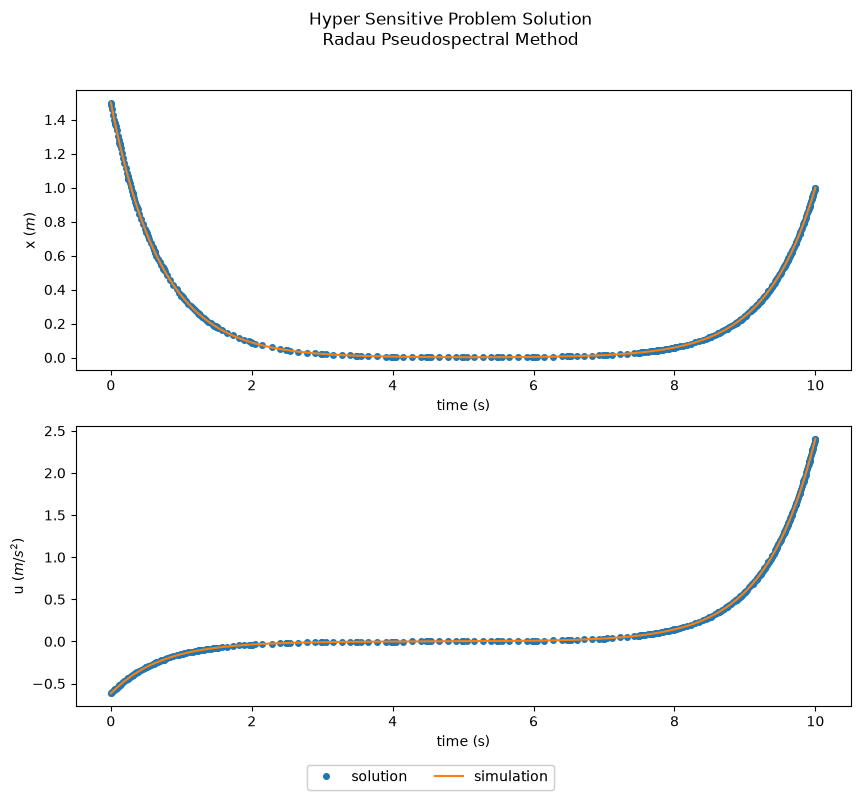

In [6]:
sol = om.CaseReader(p.get_outputs_dir() / 'dymos_solution.db').get_case('final')
sim = om.CaseReader(traj.sim_prob.get_outputs_dir() / 'dymos_simulation.db').get_case('final')

plot_results([('traj.phase0.timeseries.time', 'traj.phase0.timeseries.x',
               'time (s)', 'x $(m)$'),
              ('traj.phase0.timeseries.time', 'traj.phase0.timeseries.u',
               'time (s)', 'u $(m/s^2)$')],
             title='Hyper Sensitive Problem Solution\nRadau Pseudospectral Method',
             p_sol=sol, p_sim=sim)

plt.show()

In [7]:
from openmdao.utils.assert_utils import assert_near_equal

ui, uf, J = solution()

assert_near_equal(p.get_val('traj.phase0.timeseries.u')[0],
                  ui,
                  tolerance=1.5e-2)

assert_near_equal(p.get_val('traj.phase0.timeseries.u')[-1],
                  uf,
                  tolerance=1.5e-2)

assert_near_equal(p.get_val('traj.phase0.timeseries.xL')[-1],
                  J,
                  tolerance=1e-2)

np.float64(1.173746403017862e-06)

## References

```{bibliography}
:filter: docname in docnames
```